# Analise Multiobjetivo

O objetivo deste notebook é fazer todas as analises requeridas para a entrega 3 do TC2 contemplando Resultados, Análise baseada em indicadores de qualidade e Tomada de decisão multiatributo.

## Resultados

(a) Implemente e utilize o algoritmo apresentado no item ii.(a) para otimizar o
problema multiobjetivo construído. Caso seja utilizado algum método não exato,
então o algoritmo deve ser executado cinco vezes e as cinco fronteiras obtidas
devem ser apresentadas sobrepostas em uma mesma figura.

In [3]:
import numpy as np
import math

from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

from src.problem_model import TorqueDistributionProblem, model
from src.classes import CarParams, Reference, WeelTork, Vehicle_state
from src.vehicle_physics import generate_torque_reference, vehicle_dynamics
from src.grid import  dijkstra, dijkstra_reverso, plot_trajectory, build_cost_map

import matplotlib.pyplot as plt


In [ ]:
import matplotlib.pyplot as plt

class Fronteira:
    """
    Representa uma fronteira de Pareto para visualização e comparação.

    Armazena os valores dos objetivos das soluções não dominadas,
    além de um nome e uma cor para identificar a fronteira no gráfico.

    Parametros:
        nome (str): Nome ou identificação da fronteira.
        F (np.ndarray): Array NumPy com os valores dos objetivos.
            Deve possuir formato (n_solucoes, 2), onde cada linha
            representa uma solução e cada coluna representa um objetivo.
        cor_plot (str): Cor utilizada para representar a fronteira
            no gráfico, em formato aceito pelo Matplotlib.
    """

    def __init__(self, nome: str, F: np.ndarray, cor_plot: str):

        self.nome = nome
        self.F = F
        self.cor_plot = cor_plot


def plot_pareto(fronteiras: list[Fronteira]):
    "Plota uma lista de fronteiras pareto"
    plt.figure(figsize=(9, 6))

    for fronteira in fronteiras:
        plt.scatter(
            fronteira.F[:, 0],
            fronteira.F[:, 1],
            c=fronteira.cor_plot,
            s=35,
            alpha=0.8,
            label=fronteira.nome
        )

    plt.xlabel('Erro de momento de guinada normalizado')
    plt.ylabel('Perdas energéticas normalizadas')

    plt.title('Fronteira de Pareto - NSGA-II')

    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

A celula abaixo define os parametros do carrinho

In [5]:
# Definindo parametros do veículo
car_params = CarParams(
    wheel_radius=0.10,      # m
    gear_ratio=1.0,         # -
    track_width=0.40,       # m

    T_min=-1,              # N.m
    T_max=5,              # N.m

    loss_coeff=0.5,
    Ploss_scale=1000.0,     # W

    mass=12.0,              # kg
    yaw_inertia=0.80        # kg.m²
)

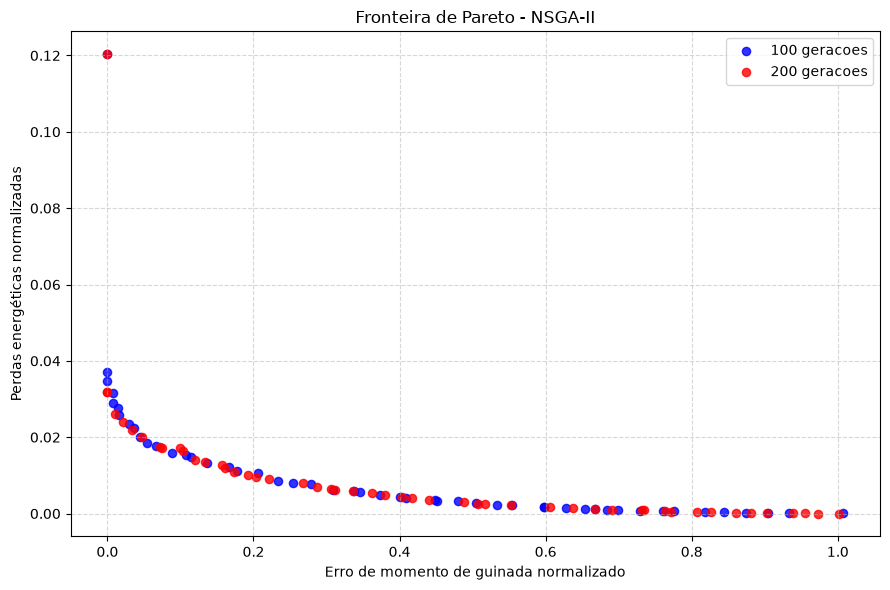

In [10]:
T_prev = WeelTork(
    Fl=0,
    Fr=0,
    Rl=0,
    Rr=0,
)

ref = Reference(
    Fx=4,
    Mz=1
)

algorithm = NSGA2(
    pop_size=50,
    eliminate_duplicates=True
)

# Cria o problema com esse torque de referencia para cada roda
problem = TorqueDistributionProblem(
    params=car_params,
    ref=ref,
    T_prev=T_prev
)

# Minimiza para encontrar o torque real
result1 = minimize(
    problem,
    algorithm,
    termination=("n_gen", 100),
    seed=1,
    verbose=False
)

# Minimiza para encontrar o torque real
result2 = minimize(
    problem,
    algorithm,
    termination=("n_gen", 200),
    seed=1,
    verbose=False
)

fronteira_1 = Fronteira(
    nome="100 geracoes",
    F=result1.F,
    cor_plot='blue'
)
fronteira_2 = Fronteira(
    nome="200 geracoes",
    F=result2.F,
    cor_plot='red'
)

plot_pareto([fronteira_1, fronteira_2])

## Análise baseada em indicadores de qualidade
Empregue os indicadores de qualidade ∆ e hipervolume (s-metric) para estimar as propriedades de convergência e diversidade da fronteira Pareto aproximada obtida. Para o cálculo de ∆ use a solução utópica (ou sua aproximação) e para a determinação do hipervolume considere um vetor de referência igual a 1.1 vezes o vetor anti-utópico. Apresente a formulação, interpretação geométrica e características gerais desses indicadores.
Caso seja utilizado algum método não exato, ambos os indicadores devem ser calculados em 10 momentos distintos, igualmente espaçados, ao longo de cada execução do algoritmo. Apresente as curvas médias de evolução de cada um dos indicadores de qualidade em função do número de iterações do algoritmo de otimização (ou do número de avaliações de soluções candidatas). Para cada indicador de qualidade, essas curvas de evolução devem ser apresentadas sobrepostas em uma mesma figura.

In [ ]:
print("Análise baseada em indicadores de qualidade")

## Tomada de decisão multiatributo

Caso tenha executado o algoritmo mais de uma vez, e as fronteiras estimadas contenham poucas soluções, considere na tomada de decisão a fronteira não-dominada obtida a partir da união de todas as fronteiras estimadas. Caso essa fronteira final contenha muitas soluções, selecione no máximo 20 soluções não-dominadas (uniformemente distribuídas ao longo da fronteira) e siga para a tomada de decisão.

Assuma como critérios de decisão pelo menos quatro (04) atributos de interesse, i.e., as duas funções objetivo definidas no problema de otimização e pelo menos mais duas funções adicionais que considerar relevantes (e.g., confiabilidade da solução frente a possíveis variações/ incertezas dos parâmetros de entrada; robustez da solução em relação a diferentes cenários de aplicação, impacto ambiental associado à solução etc.). Os atributos empregados devem ser claramente definidos e apresentados. A ideia é escolher uma configuração final(solução) que seja confiável/ robusta diante de cenários ligeiramente distintos do previsto. Para os atributos adicionais a serem propostos, a equipe tem liberdade para gerar dados extras necessários. É importante notar que esses atributos não devem estar relacionados às funções objetivo consideradas na otimização, i.e., todos os atributos de decisão devem ser conflitantes entre si!
Empregue métodos de auxílio à tomada de decisão, tais como AHP, ELECTRE, PROMETHEE e TOPSIS, para escolher a ação final a ser implementada. Use o método AHP para definir os pesos dos atributos a serem considerados. Os métodos de decisão utilizados devem ser apropriadamente definidos e apresentados. Plote uma figura contendo a fronteira de soluções avaliadas na tomada de decisão e indique, nesta figura, qual(is) solução(ões) foi(foram) escolhida(s).
Plote uma figura que represente a(s) solução(ões) final(is) escolhida(s), ilustrando suas principais características. No caso de incomparabilidade entre alternativas no final do processo, estabeleça um critério adicional e tome sua decisão. É importante notar que neste trabalho você representa a unidade de decisão e, portanto, é responsável pela definição dos pesos dos atributos e demais parâmetros que forem necessários.